# ============================================================
#  Disease Prediction ML Project
# Models: Logistic Regression + SVM
# Dataset: Heart Disease (Cleveland UCI)
# ============================================================


In [1]:

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, roc_auc_score, roc_curve)
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
import os


# ──────────────────────────────────────────────
# 1. LOAD DATA (Mohamed Mazhar)
# ──────────────────────────────────────────────



In [ ]:

import os

try:
    base_dir = os.path.dirname(os.path.abspath(__file__))
except NameError:
    
    base_dir = os.getcwd()

local_path = os.path.join(base_dir, "data", "heart.csv")

df = pd.read_csv(local_path)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [3]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [4]:
# show info
print("Shape:", df.shape)
print(df.head())
df.info()
# ──────────────────────────────────────────────
# UCI Heart Disease Dataset columns

# mazhar Done ✅


Shape: (303, 14)
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   3       145   233    1        0      150      0      2.3      0   
1   37    1   2       130   250    0        1      187      0      3.5      0   
2   41    0   1       130   204    0        0      172      0      1.4      2   
3   56    1   1       120   236    0        1      178      0      0.8      2   
4   57    0   0       120   354    0        1      163      1      0.6      2   

   ca  thal  target  
0   0     1       1  
1   0     2       1  
2   0     2       1  
3   0     2       1  
4   0     2       1  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-nu

# ──────────────────────────────────────────────
# 2. Exploratory data Analysis (yasmeen)
# ──────────────────────────────────────────────


=== 1. General Information About the Data (Info & Shape) ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB
None

Shape: (303, 14)
--------------------------------------------------

=== 2. Descriptive Statistics (Describe) ===
              age         sex         

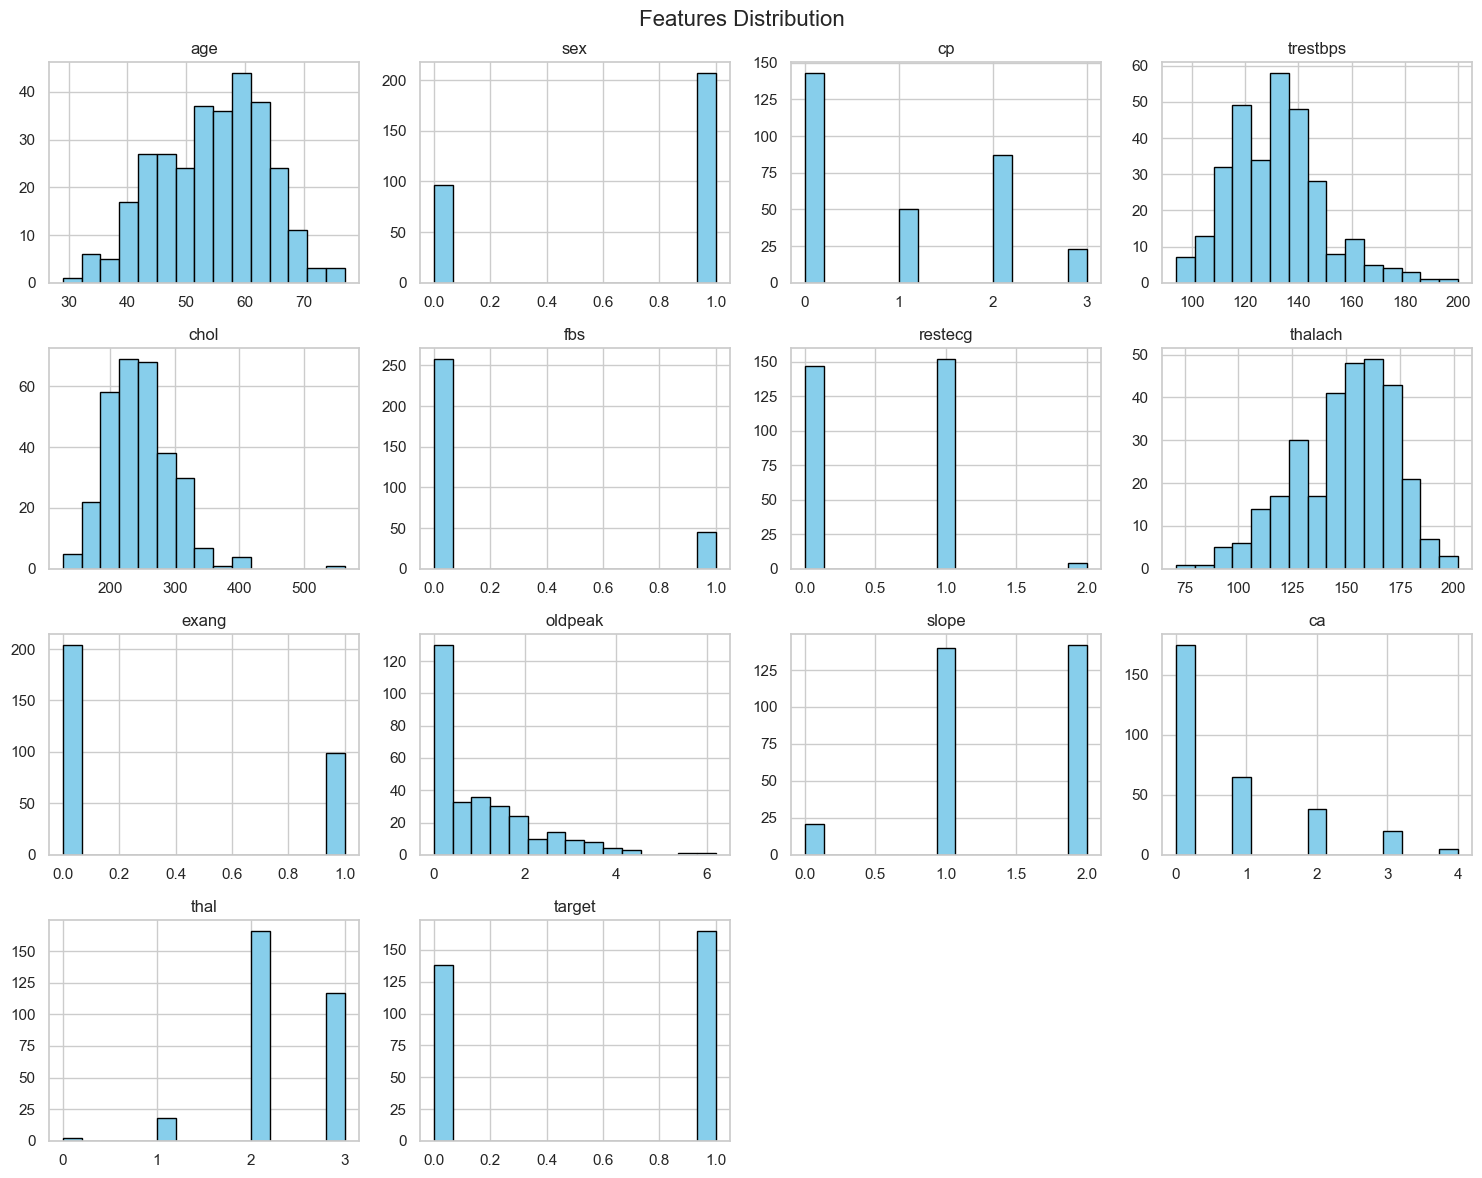


=== 5. Plotting Correlation Heatmap ===


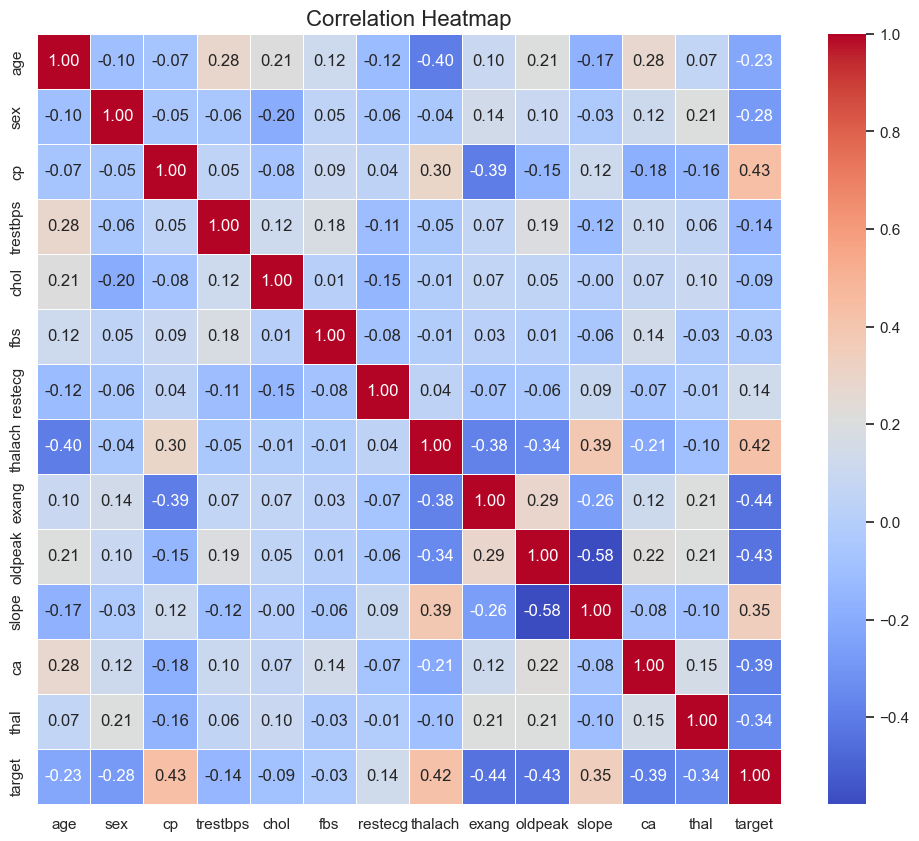


=== 6. Target Variable Distribution ===
Target Counts:
 target
1    165
0    138
Name: count, dtype: int64


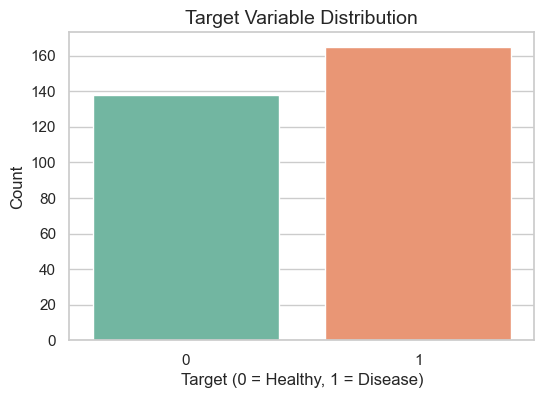

In [ ]:
# Set Seaborn theme
sns.set_theme(style="whitegrid")

# 1. Print general information about the data
print("=== 1. General Information About the Data (Info & Shape) ===")
print(df.info())
print("\nShape:", df.shape)
print("-" * 50)

# 2. Print descriptive statistics
print("\n=== 2. Descriptive Statistics (Describe) ===")
print(df.describe())
print("-" * 50)

# 3. Check for missing values
print("\n=== 3. Missing values in each column ===")
missing_data = df.isnull().sum()
print(missing_data[missing_data > 0])
print("-" * 50)

# 4. Plot the distribution for each column
print("\n=== 4. Plotting feature distributions (Histograms) ===")
df.hist(figsize=(15, 12), bins=15, color='skyblue', edgecolor='black')
plt.suptitle('Features Distribution', fontsize=16)
plt.tight_layout()
plt.show()

# 5. Plot the Correlation Heatmap
print("\n=== 5. Plotting Correlation Heatmap ===")
plt.figure(figsize=(12, 10))
correlation_matrix = df.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap', fontsize=16)
plt.show()

# 6. Distribution of the target variable (healthy vs disease)
print("\n=== 6. Target Variable Distribution ===")
target_counts = df['target'].value_counts()
print("Target Counts:\n", target_counts)

plt.figure(figsize=(6, 4))
sns.countplot(x='target', data=df, palette='Set2')
plt.title('Target Variable Distribution', fontsize=14)
plt.xlabel('Target (0 = Healthy, 1 = Disease)', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.show()



# ──────────────────────────────────────────────
# 3. PREPROCESSING (fatma )
# ──────────────────────────────────────────────


In [27]:

df = df.dropna()
df['target'] = df['target'].apply(lambda x: 1 if x > 0 else 0)

X = df.drop('target', axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

print(f"Train size: {X_train.shape}")
print(f"Test size:  {X_test.shape}")

Train size: (242, 13)
Test size:  (61, 13)


# ──────────────────────────────────────────────
# 4. MODEL 1: LOGISTIC REGRESSION (Ahmed Amin)
# ──────────────────────────────────────────────


In [7]:
print("\n" + "="*60)
print("MODEL 1: LOGISTIC REGRESSION")
print("="*60)

lr_params = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs', 'liblinear']
}
lr_grid = GridSearchCV(
    LogisticRegression(max_iter=1000),
    lr_params,
    cv=5,
    scoring='accuracy'
)
lr_grid.fit(X_train_sc, y_train)


MODEL 1: LOGISTIC REGRESSION


,estimator,LogisticRegre...max_iter=1000)
,param_grid,"{'C': [0.01, 0.1, ...], 'solver': ['lbfgs', 'liblinear']}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l2'


In [8]:
lr_best   = lr_grid.best_estimator_
y_pred_lr = lr_best.predict(X_test_sc)
y_prob_lr = lr_best.predict_proba(X_test_sc)[:, 1]

lr_acc = accuracy_score(y_test, y_pred_lr)
lr_auc = roc_auc_score(y_test, y_prob_lr)
lr_cv  = cross_val_score(lr_best, X_train_sc, y_train, cv=5).mean()

print(f"Best Params : {lr_grid.best_params_}")
print(f"Accuracy    : {lr_acc:.4f} ({lr_acc*100:.1f}%)")
print(f"ROC-AUC     : {lr_auc:.4f}")
print(f"CV Score    : {lr_cv:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, target_names=['Healthy', 'Disease']))

Best Params : {'C': 0.01, 'solver': 'liblinear'}
Accuracy    : 0.7869 (78.7%)
ROC-AUC     : 0.8820
CV Score    : 0.8432

Classification Report:
              precision    recall  f1-score   support

     Healthy       0.86      0.64      0.73        28
     Disease       0.75      0.91      0.82        33

    accuracy                           0.79        61
   macro avg       0.80      0.78      0.78        61
weighted avg       0.80      0.79      0.78        61



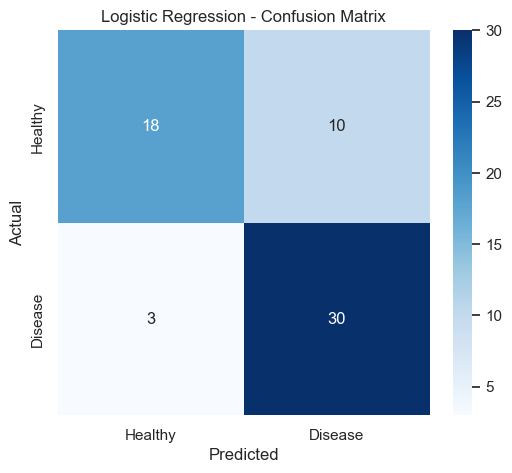

In [9]:
# Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, y_pred_lr),
            annot=True, fmt='d', cmap='Blues',
            xticklabels=['Healthy', 'Disease'],
            yticklabels=['Healthy', 'Disease'])
plt.title('Logistic Regression - Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

# ──────────────────────────────────────────────
# 5. MODEL 2: SVM & RF (Khaled Ayman)
# ──────────────────────────────────────────────

In [10]:

print("\n" + "="*60)
print("MODEL 2: SUPPORT VECTOR MACHINE (SVM)")
print("="*60)

svm_params = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}
svm_grid = GridSearchCV(
    SVC(probability=True),
    svm_params,
    cv=5,
    scoring='accuracy'
)
svm_grid.fit(X_train_sc, y_train)



MODEL 2: SUPPORT VECTOR MACHINE (SVM)


,estimator,SVC(probability=True)
,param_grid,"{'C': [0.1, 1, ...], 'gamma': ['scale', 'auto'], 'kernel': ['linear', 'rbf']}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,C,1


In [11]:
svm_best   = svm_grid.best_estimator_
y_pred_svm = svm_best.predict(X_test_sc)
y_prob_svm = svm_best.predict_proba(X_test_sc)[:, 1]

svm_acc = accuracy_score(y_test, y_pred_svm)
svm_auc = roc_auc_score(y_test, y_prob_svm)
svm_cv  = cross_val_score(svm_best, X_train_sc, y_train, cv=5).mean()

print(f"Best Params : {svm_grid.best_params_}")
print(f"Accuracy    : {svm_acc:.4f} ({svm_acc*100:.1f}%)")
print(f"ROC-AUC     : {svm_auc:.4f}")
print(f"CV Score    : {svm_cv:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm, target_names=['Healthy', 'Disease']))

Best Params : {'C': 1, 'gamma': 'scale', 'kernel': 'linear'}
Accuracy    : 0.7869 (78.7%)
ROC-AUC     : 0.8842
CV Score    : 0.8393

Classification Report:
              precision    recall  f1-score   support

     Healthy       0.86      0.64      0.73        28
     Disease       0.75      0.91      0.82        33

    accuracy                           0.79        61
   macro avg       0.80      0.78      0.78        61
weighted avg       0.80      0.79      0.78        61



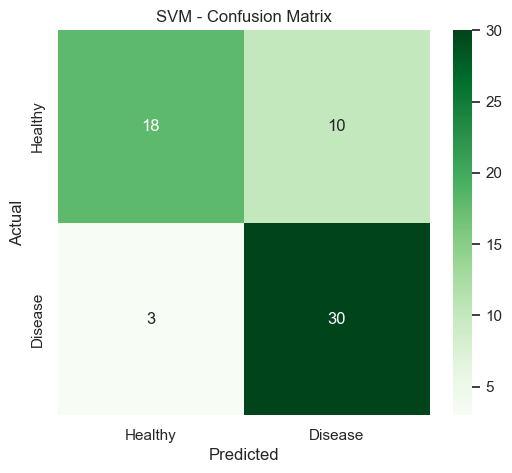

In [12]:
# Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, y_pred_svm),
            annot=True, fmt='d', cmap='Greens',
            xticklabels=['Healthy', 'Disease'],
            yticklabels=['Healthy', 'Disease'])
plt.title('SVM - Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

# ──────────────────────────────────────────────
# 6. MODEL 3: RANDOM FOREST
# ──────────────────────────────────────────────

In [14]:
print("\n" + "="*60)
print("MODEL 3: RANDOM FOREST")
print("="*60)

rf_params = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}
rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    rf_params,
    cv=5,
    scoring='accuracy',
    n_jobs=1
)
rf_grid.fit(X_train, y_train)  # Random Forest مش محتاج scaling


MODEL 3: RANDOM FOREST


,estimator,RandomForestC...ndom_state=42)
,param_grid,"{'max_depth': [None, 5, ...], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], 'n_estimators': [100, 200, ...]}"
,scoring,'accuracy'
,n_jobs,1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,200


In [15]:
rf_best   = rf_grid.best_estimator_
y_pred_rf = rf_best.predict(X_test)
y_prob_rf = rf_best.predict_proba(X_test)[:, 1]

rf_acc = accuracy_score(y_test, y_pred_rf)
rf_auc = roc_auc_score(y_test, y_prob_rf)
rf_cv  = cross_val_score(rf_best, X_train, y_train, cv=5).mean()

print(f"Best Params : {rf_grid.best_params_}")
print(f"Accuracy    : {rf_acc:.4f} ({rf_acc*100:.1f}%)")
print(f"ROC-AUC     : {rf_auc:.4f}")
print(f"CV Score    : {rf_cv:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, target_names=['Healthy', 'Disease']))

Best Params : {'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}
Accuracy    : 0.8197 (82.0%)
ROC-AUC     : 0.9113
CV Score    : 0.8392

Classification Report:
              precision    recall  f1-score   support

     Healthy       0.95      0.64      0.77        28
     Disease       0.76      0.97      0.85        33

    accuracy                           0.82        61
   macro avg       0.85      0.81      0.81        61
weighted avg       0.85      0.82      0.81        61



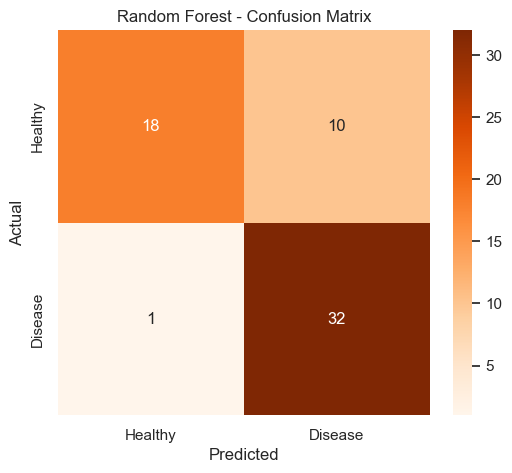

In [16]:
# Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, y_pred_rf),
            annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Healthy', 'Disease'],
            yticklabels=['Healthy', 'Disease'])
plt.title('Random Forest - Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

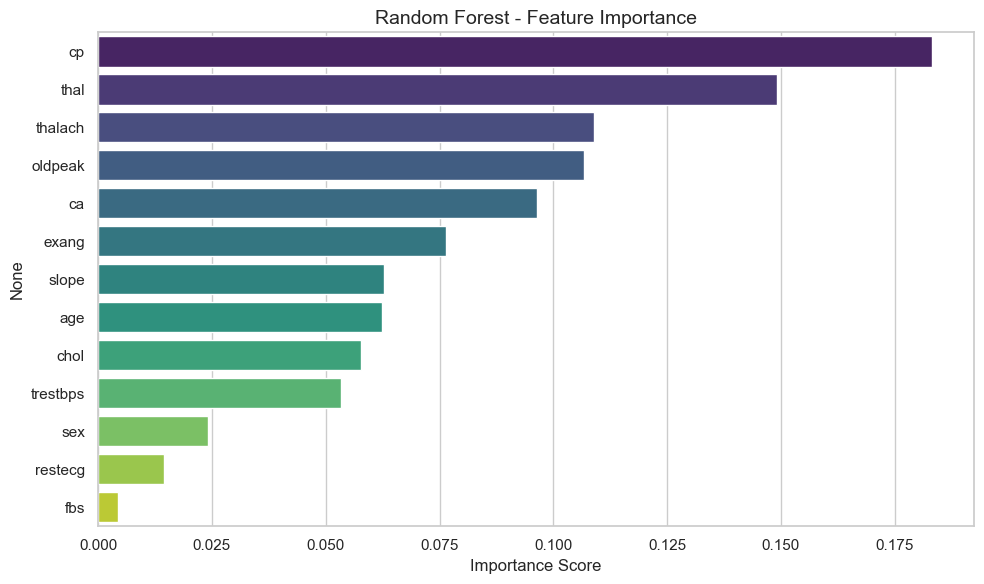


Top 5 Important Features:
cp         0.183254
thal       0.149228
thalach    0.108903
oldpeak    0.106659
ca         0.096305
dtype: float64


In [17]:
# Feature Importance
feat_imp = pd.Series(
    rf_best.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=feat_imp.values, y=feat_imp.index, palette='viridis')
plt.title('Random Forest - Feature Importance', fontsize=14)
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

print("\nTop 5 Important Features:")
print(feat_imp.head())

# ──────────────────────────────────────────────
# 7. MODEL COMPARISON (Nada)
# ──────────────────────────────────────────────


In [28]:
print("\n" + "="*60)
print("FINAL MODEL COMPARISON & EVALUATION")
print("="*60)

 
results_dict = {
    'Model': ['Logistic Regression', 'SVM', 'Random Forest'],
    'Accuracy': [lr_acc, svm_acc, rf_acc],
    'ROC-AUC': [lr_auc, svm_auc, rf_auc],
    'CV Score': [lr_cv, svm_cv, rf_cv]
}

results_df = pd.DataFrame(results_dict)


FINAL MODEL COMPARISON & EVALUATION


In [29]:
#1. Table
print("\n📊 Model Comparison Table:")
print(results_df.to_string(index=False))


📊 Model Comparison Table:
              Model  Accuracy  ROC-AUC  CV Score
Logistic Regression  0.786885 0.882035  0.843197
                SVM  0.786885 0.884199  0.839286
      Random Forest  0.819672 0.911255  0.839201


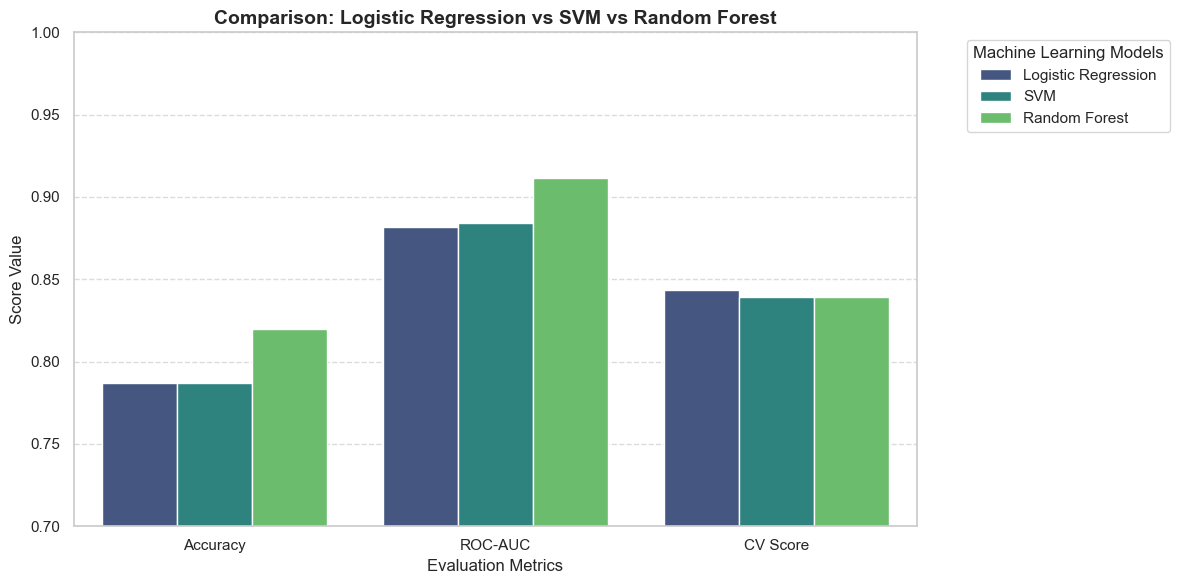

In [30]:
# 2. Bar Chart 
results_melted = results_df.melt(id_vars='Model', var_name='Metric', value_name='Score')

plt.figure(figsize=(12, 6))
sns.barplot(x='Metric', y='Score', hue='Model', data=results_melted, palette='viridis')
plt.title('Comparison: Logistic Regression vs SVM vs Random Forest', fontsize=14, fontweight='bold')
plt.ylim(0.7, 1.0)  
plt.ylabel('Score Value')
plt.xlabel('Evaluation Metrics')
plt.legend(title='Machine Learning Models', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


In [31]:
# 3.Winner based on ROC-AUC 
winner = results_df.loc[results_df['ROC-AUC'].idxmax()]
print("\n" + "⭐"*30)
print(f"🏆 THE WINNER MODEL IS: {winner['Model']} 🏆")
print(f"Highest ROC-AUC Score: {winner['ROC-AUC']:.4f}")
print("⭐"*30)


⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐
🏆 THE WINNER MODEL IS: Random Forest 🏆
Highest ROC-AUC Score: 0.9113
⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐


In [32]:
# 4.Dictionary of results
final_results_summary = results_dict

# ──────────────────────────────────────────────
# 8. SAVE RESULTS (Khaled Ayman)
# ──────────────────────────────────────────────


In [23]:
print("\n" + "="*60)
print("SAVING RESULTS TO CSV")
print("="*60)

results_df.to_csv("results.csv", index=False)

print("✅ Results saved successfully as 'results.csv'")
print("PROJECT EXECUTION COMPLETED!")
print("="*60)


SAVING RESULTS TO CSV
✅ Results saved successfully as 'results.csv'
PROJECT EXECUTION COMPLETED!
